# Análisis Exploratorio de Datos (EDA) y Decisiones de Modelado
## Proyecto: Estimación de Precios de Airbnb en Buenos Aires

Este notebook resume las características principales del conjunto de datos de Inside Airbnb (Buenos Aires), inspecciona las variables a utilizar, aplica la limpieza de datos y fundamenta las decisiones metodológicas de los Ejercicios 3 y 6.

## 1. Importación de Librerías y Carga de Datos
Cargamos los datos crudos utilizando las funciones del proyecto.

In [1]:
import sys
from pathlib import Path

# Aseguramos que la raíz del proyecto y src estén en la ruta de búsqueda de módulos
raiz = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
for p in [str(raiz), str(raiz / 'src')]:
    if p not in sys.path:
        sys.path.insert(0, p)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pipeline import cargar_datos, preparar

# Carga de datos
df_raw = cargar_datos()
print('Dimensiones del dataset:', df_raw.shape)
df_raw[['name', 'room_type', 'accommodates', 'bedrooms', 'beds', 'minimum_nights', 'number_of_reviews', 'price_num']].head()

Dimensiones del dataset: (29753, 91)


,name,room_type,accommodates,bedrooms,beds,minimum_nights,number_of_reviews,price_num
0,Amazing Luxurious Apt-Palermo Soho,Entire home/apt,2,1.0,1.0,3.0,52,186530.00
1,Excelente ubicación 2amb grandes Balcon propio,Entire home/apt,2,1.0,1.0,2.0,1,91729.00
2,PENTHOUSE /Terrace & pool /City views /2bedrooms,Entire home/apt,4,2.0,2.0,2.0,394,232074.07
3,"Teatro Gran Rex, Tribunales, Obelisco, Subte ...",Entire home/apt,3,1.0,2.0,1.0,393,117408.00
4,Amazing LOFTpalermo: contemporary and cool,Entire home/apt,2,1.0,1.0,12.0,37,465014.50


## 2. Resumen Estadístico General (`describe`)
Examinamos las columnas numéricas principales que utilizaremos en los ejercicios para entender sus escalas, valores mínimos, medios y máximos.

In [2]:
columnas_interes = ["price_num", "accommodates", "bedrooms", "beds", "minimum_nights", "number_of_reviews"]

print("--- Conteo de Valores Ausentes ---")
print(df_raw[columnas_interes].isna().sum())

print("\n--- Resumen Estadístico Básico ---")
df_raw[columnas_interes].describe().round(2)

--- Conteo de Valores Ausentes ---
price_num            2119
accommodates            0
bedrooms               13
beds                  522
minimum_nights          1
number_of_reviews       0
dtype: int64

--- Resumen Estadístico Básico ---


,price_num,accommodates,bedrooms,beds,minimum_nights,number_of_reviews
count,2.763400e+04,29753.00,29740.00,29231.00,29752.00,29753.00
mean,2.777668e+05,2.94,1.15,1.94,4.90,41.74
std,3.545175e+06,1.59,0.94,1.58,18.59,61.56
min,2.465900e+02,1.00,0.00,1.00,1.00,0.00
25%,7.949850e+04,2.00,1.00,1.00,1.00,4.00
50%,1.063930e+05,2.00,1.00,1.00,2.00,18.00
75%,1.486772e+05,4.00,1.00,2.00,3.00,55.00
max,1.605638e+08,16.00,31.00,50.00,730.00,1155.00


## 3. Inspección del Precio y Filtro de Extremos

Al observar el precio nocturno notamos dos situaciones clave:
1. **Precios no válidos:** existen valores ausentes o menores/iguales a cero.
2. **Valores atípicos extremos:** el precio máximo supera los 160 millones de pesos (errores de tipeo o valores ficticios), distorsionando el promedio general (~$277.767 ARS) respecto de la mediana (~$106.393 ARS).

> **Decisión simple:** Se eliminan los valores ausentes o no positivos y se recorta entre el **percentil 1% y 99%** para conservar el 98% de anuncios reales y representativos de Buenos Aires.

In [3]:
precios_validos = df_raw["price_num"].dropna()
precios_validos = precios_validos[precios_validos > 0]

q01, q99 = precios_validos.quantile([0.01, 0.99])
print("Límite inferior (Percentil 1%):  $", round(q01, 2))
print("Límite superior (Percentil 99%): $", round(q99, 2))

precios_filtrados = precios_validos[precios_validos.between(q01, q99)]

print("\nRegistros antes del filtro:", len(precios_validos))
print("Registros post-filtro:     ", len(precios_filtrados))
print("Precio promedio post-filtro: $", round(precios_filtrados.mean(), 2))
print("Precio mediano post-filtro:  $", round(precios_filtrados.median(), 2))

Límite inferior (Percentil 1%):  $ 26907.14
Límite superior (Percentil 99%): $ 899463.19

Registros antes del filtro: 27634
Registros post-filtro:      27086
Precio promedio post-filtro: $ 129895.46
Precio mediano post-filtro:  $ 106381.68


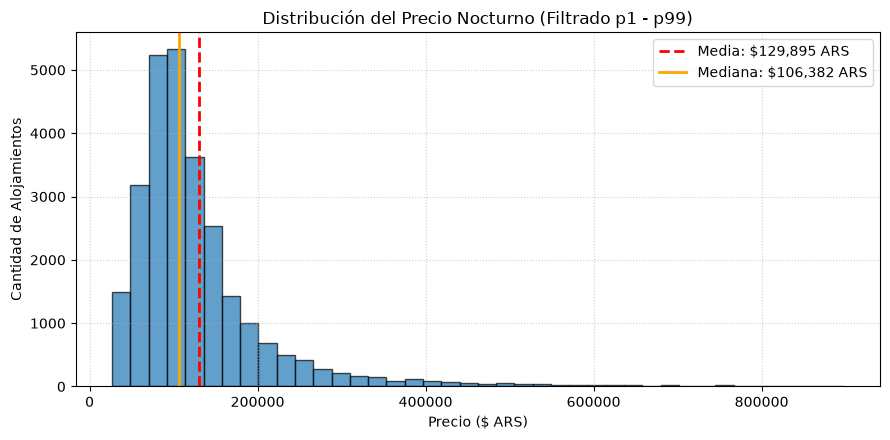

In [4]:
plt.figure(figsize=(9, 4.5))
plt.hist(precios_filtrados, bins=40, color="#1f77b4", edgecolor="black", alpha=0.7)
plt.axvline(precios_filtrados.mean(), color="red", linestyle="--", linewidth=2, label=f"Media: ${precios_filtrados.mean():,.0f} ARS")
plt.axvline(precios_filtrados.median(), color="orange", linestyle="-", linewidth=2, label=f"Mediana: ${precios_filtrados.median():,.0f} ARS")
plt.title("Distribución del Precio Nocturno (Filtrado p1 - p99)")
plt.xlabel("Precio ($ ARS)")
plt.ylabel("Cantidad de Alojamientos")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

## 4. Inspección de Variables de los Ejercicios

### Ejercicio 3: ¿Influyen las reseñas en el precio?
Analizamos si un anuncio con muchas reseñas tiende a costar más que uno con pocas.

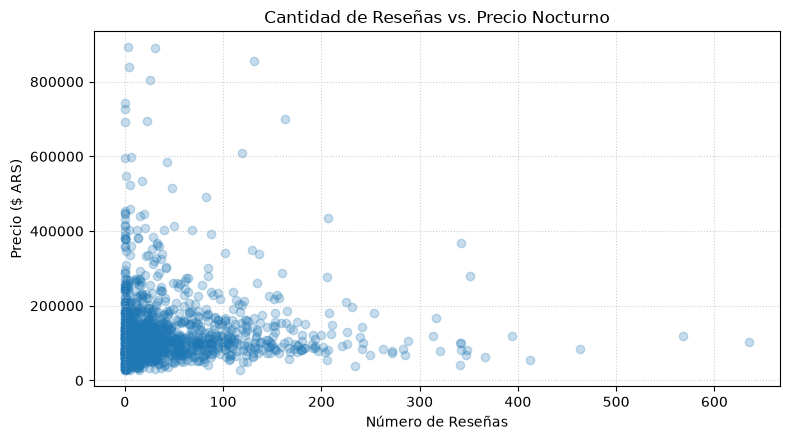

Precio promedio con pocas reseñas (<= 5):  $ 133481.08
Precio promedio con muchas reseñas (> 50):  $ 130965.53


In [5]:
df_ej3 = preparar(df_raw, ["number_of_reviews"])
muestra = df_ej3.sample(min(1500, len(df_ej3)), random_state=42)

plt.figure(figsize=(8, 4.5))
plt.scatter(muestra["number_of_reviews"], muestra["price_num"], alpha=0.25, color="#1f77b4")
plt.title("Cantidad de Reseñas vs. Precio Nocturno")
plt.xlabel("Número de Reseñas")
plt.ylabel("Precio ($ ARS)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

print("Precio promedio con pocas reseñas (<= 5):  $", round(df_ej3[df_ej3["number_of_reviews"] <= 5]["price_num"].mean(), 2))
print("Precio promedio con muchas reseñas (> 50):  $", round(df_ej3[df_ej3["number_of_reviews"] > 50]["price_num"].mean(), 2))

> **Observación simple:** Los precios promedio para pocas y muchas reseñas son prácticamente iguales (~$130.000 ARS). La cantidad de reseñas no cambia el precio del alojamiento.

### Ejercicio 6: Capacidad del alojamiento y precio
En cambio, las variables de capacidad física (`accommodates`, `bedrooms`, `beds`) sí muestran una relación directa y esperable con el precio.

In [6]:
df_ej6 = preparar(df_raw, ["accommodates", "bedrooms", "beds", "minimum_nights", "number_of_reviews"])

print("--- Precio Promedio según Capacidad de Huéspedes ---")
promedios_capacidad = df_ej6.groupby("accommodates")["price_num"].agg(["count", "mean", "median"]).head(6)
promedios_capacidad.columns = ["Cantidad", "Precio Medio ($ ARS)", "Precio Mediano ($ ARS)"]
promedios_capacidad.round(2)

--- Precio Promedio según Capacidad de Huéspedes ---


,Cantidad,Precio Medio ($ ARS),Precio Mediano ($ ARS)
accommodates,,,
1,1083,58722.38,47103.00
2,12973,107725.64,94990.35
3,4708,123129.63,107017.50
4,5425,151047.55,129605.40
5,1026,198436.86,171000.66
6,819,240769.75,206543.00


## 5. Decisiones Clave para el Modelado

A partir de las características observadas en los datos, se definen las siguientes decisiones simples y directas:

1. **Ejercicio 3 (Regresión Lineal Simple):**
   - Se busca contrastar si existe una relación directa entre una única variable continua (`number_of_reviews`) y el precio.
   - La regresión lineal simple es el modelo adecuado por su facilidad de interpretación en coeficientes directos (pesos por reseña).

2. **Ejercicio 6 (k-NN para Regresión):**
   - Se busca estimar el precio buscando los alojamientos más parecidos (vecinos cercanos).
   - **Estandarización (`StandardScaler`):** Las escalas son muy distintas (noches mínimas va hasta 365, mientras dormitorios va de 1 a 5). Se escalan las variables para que ninguna distorsione el cálculo de distancias euclidianas.
   - **Ponderación por distancia (`weights="distance"`):** Se da mayor peso a los vecinos que son prácticamente idénticos en atributos respecto a los que están más lejos dentro del grupo de $k$ vecinos.
   - **Validación Cruzada (5 pliegues):** Se prueban valores de $k \in [3, 5, 7, 9, 11, 15]$ en el conjunto de entrenamiento para elegir aquel que produzca el menor error (RMSE) antes de evaluar en datos de prueba.